# Load data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("data/hour_bike_sharing_data.csv")
print(f"Shape: {df.shape}")
print(f"Missing values: {df.isnull().sum().sum()} | Duplicate rows: {df.duplicated().sum()}")
assert (df["casual"] + df["registered"] == df["cnt"]).all(), "Target leakage sum mismatch"

df["date"] = pd.to_datetime(df["dteday"], format="%d/%m/%y")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")

df_clean = df.drop(columns=["instant", "dteday", "casual", "registered"])
df_clean.describe().T[["count", "mean", "std", "min", "50%", "max"]]

Shape: (17379, 17)
Missing values: 0 | Duplicate rows: 0
Date range: 2011-01-01 to 2012-12-31


,count,mean,std,min,50%,max
season,17379.0,2.50164,1.106918,1.0,3.0,4.0
yr,17379.0,0.502561,0.500008,0.0,1.0,1.0
mnth,17379.0,6.537775,3.438776,1.0,7.0,12.0
hr,17379.0,11.546752,6.914405,0.0,12.0,23.0
holiday,17379.0,0.02877,0.167165,0.0,0.0,1.0
weekday,17379.0,3.003683,2.005771,0.0,3.0,6.0
workingday,17379.0,0.682721,0.465431,0.0,1.0,1.0
weathersit,17379.0,1.425283,0.639357,1.0,1.0,4.0
temp,17379.0,0.496987,0.192556,0.02,0.5,1.0
atemp,17379.0,0.475775,0.17185,0.0,0.4848,1.0


# EDA

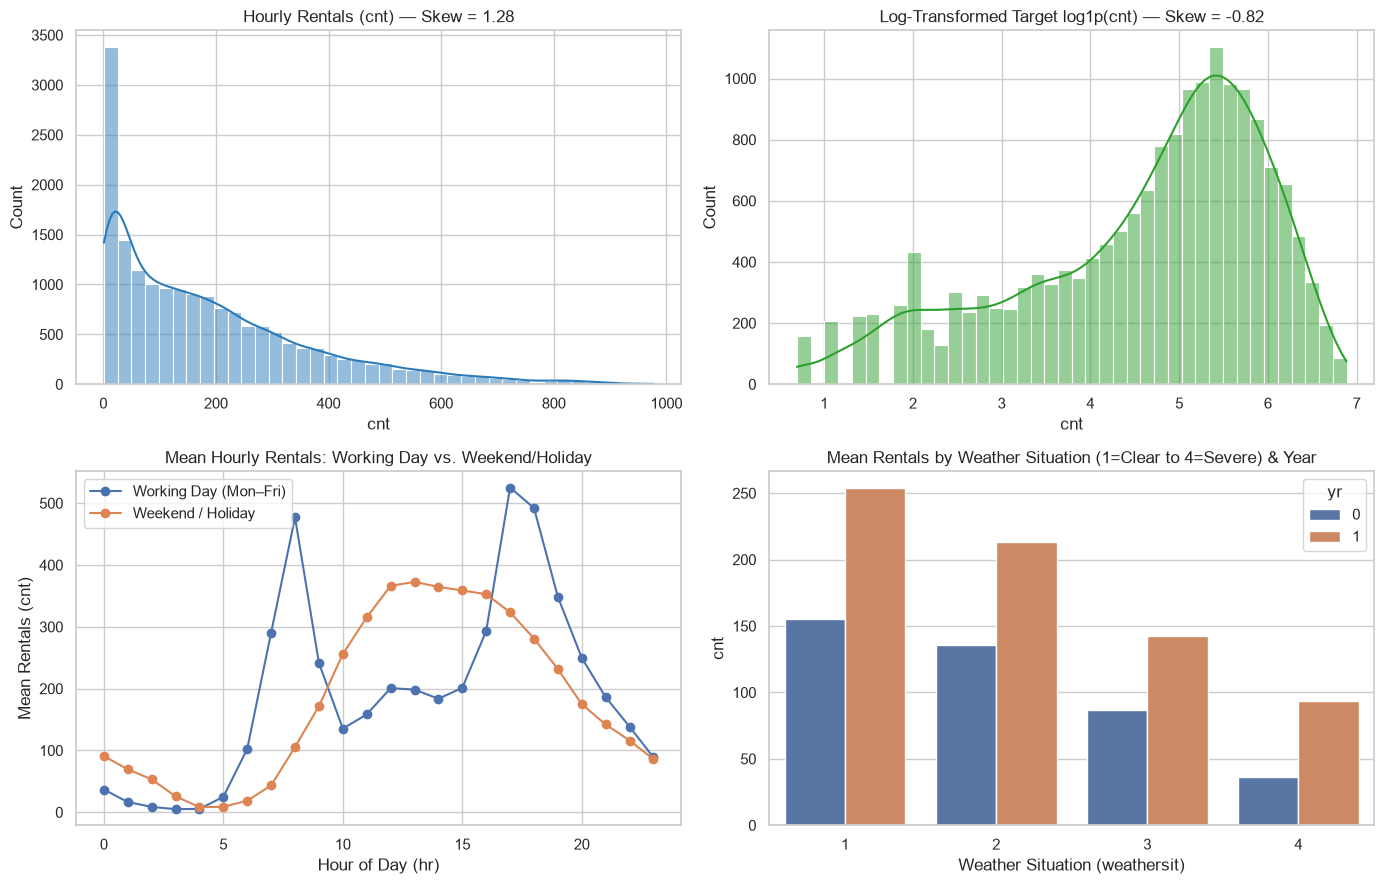

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# raw vs log1p
sns.histplot(df_clean["cnt"], bins=40, kde=True, ax=axes[0, 0], color="#2b7bba")
axes[0, 0].set_title(f"Hourly Rentals (cnt) — Skew = {df_clean['cnt'].skew():.2f}")

sns.histplot(np.log1p(df_clean["cnt"]), bins=40, kde=True, ax=axes[0, 1], color="#2ca02c")
axes[0, 1].set_title(f"Log-Transformed Target log1p(cnt) — Skew = {np.log1p(df_clean['cnt']).skew():.2f}")

# commuter vs weekend hourly demand interaction
for wd, label in [(1, "Working Day (Mon–Fri)"), (0, "Weekend / Holiday")]:
    hourly = df_clean[df_clean["workingday"] == wd].groupby("hr")["cnt"].mean()
    axes[1, 0].plot(hourly.index, hourly.values, marker="o", label=label)
axes[1, 0].set_title("Mean Hourly Rentals: Working Day vs. Weekend/Holiday")
axes[1, 0].set_xlabel("Hour of Day (hr)")
axes[1, 0].set_ylabel("Mean Rentals (cnt)")
axes[1, 0].legend()

# weather situation & yearly growth
sns.barplot(data=df_clean, x="weathersit", y="cnt", hue="yr", ax=axes[1, 1], errorbar=None)
axes[1, 1].set_title("Mean Rentals by Weather Situation (1=Clear to 4=Severe) & Year")
axes[1, 1].set_xlabel("Weather Situation (weathersit)")

plt.tight_layout()
plt.show()

# split, model comparison & feature importance

                  model  val RMSE  val MAE
               lightGBM     84.75    55.78
          random forest     86.11    56.50
                XGBoost    101.36    66.41
ridge (linear baseline)    129.87    92.01


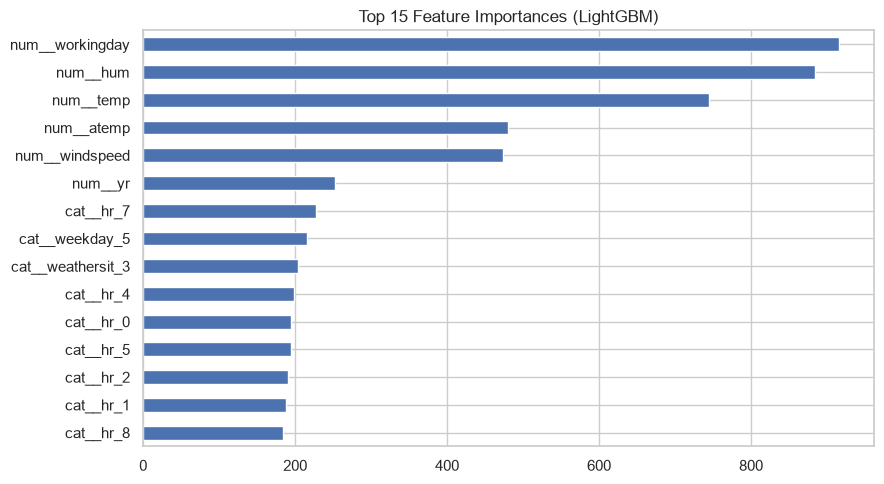

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

# split data
train = df_clean[df_clean["date"] < "2012-09-01"].drop(columns=["date"])
val = df_clean[(df_clean["date"] >= "2012-09-01") & (df_clean["date"] < "2012-11-01")].drop(columns=["date"])
test = df_clean[df_clean["date"] >= "2012-11-01"].drop(columns=["date"])

X_train, y_train_log = train.drop(columns=["cnt"]), np.log1p(train["cnt"])
X_val, y_val_raw = val.drop(columns=["cnt"]), val["cnt"].values
X_test, y_test_raw = test.drop(columns=["cnt"]), test["cnt"].values

cat_cols = ["season", "mnth", "hr", "weekday", "weathersit"]
num_cols = ["yr", "holiday", "workingday", "temp", "atemp", "hum", "windspeed"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols),
])

models = {
    "ridge (linear baseline)": Ridge(alpha=1.0),
    "random forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "lightGBM": LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42),
}

results = []
fitted_pipelines = {}

for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train_log)
    preds = np.clip(np.expm1(pipe.predict(X_val)), 0, None)
    results.append({
        "model": name,
        "val RMSE": round(root_mean_squared_error(y_val_raw, preds), 2),
        "val MAE": round(mean_absolute_error(y_val_raw, preds), 2),
    })
    fitted_pipelines[name] = pipe

results_df = pd.DataFrame(results).sort_values("val RMSE")
print(results_df.to_string(index=False))

# feature importance analysis from lgbm
lgbm_pipe = fitted_pipelines["lightGBM"]
feature_names = lgbm_pipe.named_steps["prep"].get_feature_names_out()
importances = pd.Series(lgbm_pipe.named_steps["model"].feature_importances_, index=feature_names)
importances.nlargest(15).sort_values().plot(kind="barh", figsize=(9, 5), title="Top 15 Feature Importances (LightGBM)")
plt.tight_layout()
plt.show()

# hyperparameter tuning & evaluation

In [9]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

tscv = TimeSeriesSplit(n_splits=5)

# tune lGBM
lgbm_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LGBMRegressor(random_state=42, verbose=-1)),
])
lgbm_params = {
    "model__n_estimators": [300, 500, 800],
    "model__learning_rate": [0.02, 0.05, 0.08],
    "model__num_leaves": [31, 63, 127],
    "model__min_child_samples": [10, 20, 40],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
}
lgbm_search = RandomizedSearchCV(
    lgbm_pipe,
    param_distributions=lgbm_params,
    n_iter=15,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
)
lgbm_search.fit(X_train, y_train_log)

# tune xgboost
xgb_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", XGBRegressor(random_state=42, n_jobs=-1)),
])
xgb_params = {
    "model__n_estimators": [300, 500, 800],
    "model__learning_rate": [0.02, 0.05, 0.08],
    "model__max_depth": [4, 6, 8],
    "model__min_child_weight": [1, 5, 10],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
}
xgb_search = RandomizedSearchCV(
    xgb_pipe,
    param_distributions=xgb_params,
    n_iter=15,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
)
xgb_search.fit(X_train, y_train_log)

# compare tuned models on validation set
tuned_candidates = {
    "lightGBM (tuned)": lgbm_search.best_estimator_,
    "XGBoost (tuned)": xgb_search.best_estimator_,
}

tuned_rows = []
for name, est in tuned_candidates.items():
    val_preds = np.clip(np.expm1(est.predict(X_val)), 0, None)
    tuned_rows.append({
        "model": name,
        "val RMSE": round(root_mean_squared_error(y_val_raw, val_preds), 2),
        "val MAE": round(mean_absolute_error(y_val_raw, val_preds), 2),
    })

tuned_df = pd.DataFrame(tuned_rows).sort_values("val RMSE")
print("=== tuned validation comparison ===")
print(tuned_df.to_string(index=False))

best_name = tuned_df.iloc[0]["model"]
best_search = lgbm_search if "lightGBM" in best_name else xgb_search
print(f"\nbest model: {best_name}")
print("best hyperparameters:", best_search.best_params_)

# retrain best model on train + val and evaluate once on test data
X_full_train = pd.concat([X_train, X_val], axis=0)
y_full_train_log = np.log1p(np.concatenate([train["cnt"].values, y_val_raw]))

final_model = best_search.best_estimator_
final_model.fit(X_full_train, y_full_train_log)

test_preds = np.clip(np.expm1(final_model.predict(X_test)), 0, None)
print(f"\n=== final test set performance (nov–dec 2012) ===")
print(f"test RMSE: {root_mean_squared_error(y_test_raw, test_preds):.2f}")
print(f"test MAE:  {mean_absolute_error(y_test_raw, test_preds):.2f}")

=== tuned validation comparison ===
           model  val RMSE  val MAE
lightGBM (tuned)     78.33    51.38
 XGBoost (tuned)     86.95    57.61

best model: lightGBM (tuned)
best hyperparameters: {'model__subsample': 0.8, 'model__num_leaves': 31, 'model__n_estimators': 300, 'model__min_child_samples': 10, 'model__learning_rate': 0.08, 'model__colsample_bytree': 0.8}

=== final test set performance (nov–dec 2012) ===
test RMSE: 67.52
test MAE:  43.62
